### DOKUMENTASI EKSPERIMEN AWAL – YOLO26n SEGMENTATION

**PERHATIAN: Notebook ini merupakan eksperimen terdahulu dan tidak digunakan sebagai pipeline utama PANGANITA.**

Eksperimen ini menggunakan model YOLO26n-seg (`yolo26n-seg.pt`) dengan pendekatan Instance Segmentation untuk mengenali objek sekaligus menghasilkan mask area objek.

**Tahapan eksperimen:**
1. Analisis dan pemeriksaan dataset.
2. Konversi anotasi LabelMe JSON ke format YOLO Segmentation.
3. Pembagian dataset menggunakan Stratified Split.
4. Fine-tuning YOLO26n-seg.
5. Evaluasi hasil training.
6. Pengujian dan visualisasi segmentasi.

**Alasan tidak digunakan:** Pendekatan ini tidak dipilih sebagai pipeline final karena hasil eksperimen belum memenuhi kebutuhan sistem secara konsisten.

Pengembangan utama kemudian dialihkan ke YOLO26n Detection yang didokumentasikan dalam notebook `eksperimen_yolo26_detect.ipynb`.

Notebook ini dipertahankan sebagai dokumentasi eksperimen dan pembelajaran pengembangan Computer Vision PANGANITA.

In [29]:

import json
import random
import shutil
from pathlib import Path
from PIL import Image



In [40]:

# ==================================================
# 1. KONFIGURASI PROYEK
# ==================================================

ROOT = Path.cwd()

SOURCE = ROOT / "foto-mentah"
OUTPUT = ROOT / "dataset-yolo"

CLASSES = [
    "wortel",
    "udang",
    "singkong",
    "pisang",
    "ubi_jalar",
    "jagung",
    "tomat",
    "ikan_lele",
    "ikan_kembung",
    "ikan_tongkol",
    "ikan_gurame",
    "bayam",
    "kangkung",
    "buah_naga",
    "telur_ayam_ras"
]

CLASS_MAP = {name: i for i, name in enumerate(CLASSES)}

EXTENSIONS = {".jpg", ".jpeg", ".png", ".webp"}

random.seed(42)

print("ROOT:", ROOT)
print("SOURCE:", SOURCE)
print("OUTPUT:", OUTPUT)

if not SOURCE.exists():
    raise FileNotFoundError("Folder foto-mentah tidak ditemukan!")



ROOT: c:\Users\LENOVO\Music\panganita-cv
SOURCE: c:\Users\LENOVO\Music\panganita-cv\foto-mentah
OUTPUT: c:\Users\LENOVO\Music\panganita-cv\dataset-yolo


In [41]:
# ==================================================
# 2. BERSIHKAN OUTPUT LAMA
# ==================================================

if OUTPUT.exists():
    shutil.rmtree(OUTPUT)

OUTPUT.mkdir(parents=True, exist_ok=True)

print("\nFolder dataset lama dibersihkan.")




Folder dataset lama dibersihkan.


In [42]:
# ==================================================
# 3. MEMBACA FOTO DAN ANOTASI JSON
# ==================================================

pairs = []
missing_json = []
invalid = []
empty_annotations = []

image_files = sorted([
    f for f in SOURCE.iterdir()
    if f.is_file() and f.suffix.lower() in EXTENSIONS
])

for image_path in image_files:

    json_path = image_path.with_suffix(".json")

    # Lewati foto yang sengaja tidak dianotasi
    if not json_path.exists():
        missing_json.append(image_path.name)
        continue

    try:
        with open(json_path, "r", encoding="utf-8") as f:
            data = json.load(f)

        with Image.open(image_path) as img:
            width, height = img.size

        labels = []

        for shape in data.get("shapes", []):

            label = (
                shape.get("label", "")
                .strip()
                .lower()
                .replace("-", "_")
                .replace(" ", "_")
            )

            points = shape.get("points", [])

            # Pastikan kelas tersedia
            if label not in CLASS_MAP:
                invalid.append(
                    f"{image_path.name}: kelas '{label}' tidak dikenal"
                )
                continue

            # Polygon minimal memiliki 3 titik
            if not isinstance(points, list) or len(points) < 3:
                invalid.append(
                    f"{image_path.name}: polygon kurang dari 3 titik"
                )
                continue

            valid_points = []

            for point in points:
                if len(point) != 2:
                    continue

                x, y = point

                if not (
                    isinstance(x, (int, float))
                    and isinstance(y, (int, float))
                    and math.isfinite(x)
                    and math.isfinite(y)
                ):
                    continue

                # Normalisasi koordinat
                x = max(0, min(1, x / width))
                y = max(0, min(1, y / height))

                valid_points.append((x, y))

            if len(valid_points) < 3:
                invalid.append(
                    f"{image_path.name}: koordinat polygon tidak valid"
                )
                continue

            labels.append((label, valid_points))

        if labels:
            pairs.append(
                (image_path, width, height, labels)
            )
        else:
            empty_annotations.append(image_path.name)

    except Exception as e:
        invalid.append(
            f"{image_path.name}: {str(e)}"
        )



In [43]:
# ==================================================
# 4. PEMERIKSAAN DUPLIKAT NAMA FILE
# ==================================================

seen_stems = set()
unique_pairs = []

for item in pairs:

    image_path = item[0]
    stem = image_path.stem.lower()

    if stem in seen_stems:
        invalid.append(
            f"{image_path.name}: nama dasar file duplikat"
        )
        continue

    seen_stems.add(stem)
    unique_pairs.append(item)

pairs = unique_pairs

print("\n=== HASIL PEMBACAAN DATASET ===")
print("Total foto ditemukan:", len(image_files))
print("Foto dengan polygon valid:", len(pairs))
print("Foto tanpa JSON:", len(missing_json))
print("JSON kosong/tanpa polygon valid:", len(empty_annotations))
print("Anotasi bermasalah:", len(invalid))




=== HASIL PEMBACAAN DATASET ===
Total foto ditemukan: 162
Foto dengan polygon valid: 151
Foto tanpa JSON: 11
JSON kosong/tanpa polygon valid: 0
Anotasi bermasalah: 0


In [44]:
# ==================================================
# 5. PEMBAGIAN DATASET 70:20:10
# ==================================================

random.shuffle(pairs)

n = len(pairs)

n_train = int(n * 0.70)
n_val = int(n * 0.20)

splits = {
    "train": pairs[:n_train],
    "val": pairs[n_train:n_train + n_val],
    "test": pairs[n_train + n_val:]
}



In [45]:
# ==================================================
# 6. MEMBUAT STRUKTUR FOLDER YOLO
# ==================================================

for split in splits:

    (OUTPUT / "images" / split).mkdir(
        parents=True,
        exist_ok=True
    )

    (OUTPUT / "labels" / split).mkdir(
        parents=True,
        exist_ok=True
    )



In [46]:
# ==================================================
# 7. KONVERSI POLYGON KE YOLO SEGMENTATION
# ==================================================

for split, items in splits.items():

    for image_path, width, height, labels in items:

        # Salin gambar
        shutil.copy2(
            image_path,
            OUTPUT / "images" / split / image_path.name
        )

        txt_path = (
            OUTPUT / "labels" / split /
            f"{image_path.stem}.txt"
        )

        with open(txt_path, "w", encoding="utf-8") as f:

            for label, points in labels:

                class_id = CLASS_MAP[label]

                coordinates = []

                for x, y in points:
                    coordinates.append(f"{x:.6f}")
                    coordinates.append(f"{y:.6f}")

                line = (
                    str(class_id) + " " +
                    " ".join(coordinates)
                )

                f.write(line + "\n")



In [47]:
# ==================================================
# 8. MEMBUAT DATA.YAML
# ==================================================

yaml_content = [
    f"path: '{OUTPUT.as_posix()}'",
    "train: images/train",
    "val: images/val",
    "test: images/test",
    "",
    "names:"
]

for i, name in enumerate(CLASSES):
    yaml_content.append(f"  {i}: {name}")

with open(
    OUTPUT / "data.yaml",
    "w",
    encoding="utf-8"
) as f:
    f.write("\n".join(yaml_content) + "\n")



In [48]:
# ==================================================
# 9. LAPORAN DATASET
# ==================================================

print("\n===================================")
print("       DATASET PANGANITA")
print("===================================")

for split, items in splits.items():

    jumlah_objek = sum(
        len(item[3]) for item in items
    )

    print(
        f"{split.upper():5} : "
        f"{len(items)} foto | "
        f"{jumlah_objek} objek"
    )

print("-----------------------------------")
print("Total foto digunakan:", len(pairs))
print(
    "Total objek:",
    sum(len(item[3]) for item in pairs)
)
print("Jumlah kelas:", len(CLASSES))
print("Lokasi:", OUTPUT)

# ==================================================
# 10. LAPORAN FOTO YANG DILEWATI
# ==================================================

if missing_json:

    print("\nFOTO TANPA JSON (DILEWATI):")

    for name in missing_json:
        print("-", name)

if empty_annotations:

    print("\nFOTO TANPA POLYGON VALID:")

    for name in empty_annotations:
        print("-", name)

if invalid:

    print("\nANOTASI BERMASALAH:")

    for name in invalid:
        print("-", name)

print("\n===================================")
print("KONVERSI DATASET SELESAI!")
print("===================================")



       DATASET PANGANITA
TRAIN : 105 foto | 164 objek
VAL   : 30 foto | 50 objek
TEST  : 16 foto | 42 objek
-----------------------------------
Total foto digunakan: 151
Total objek: 256
Jumlah kelas: 15
Lokasi: c:\Users\LENOVO\Music\panganita-cv\dataset-yolo

FOTO TANPA JSON (DILEWATI):
- bayam-dapat-dipanen-dengan-memetik-daun-bagian-luar-dan-membiarkan-daun-muda-di-bagian-tengah-terus-tumbuh-balcony-garden-web-jBBtp.jpg
- ikanlele8.jpg
- ikantongkol8.jpg
- kangkung4.jpg
- kangkung5.jpg
- kangkung_1.jpg
- kangkung_4.jpg
- Spinach_1.jpg
- Spinach_leaves.jpg
- telur_jpg.rf.88dbef1271d748f476cd9147dadaec72.jpg
- tongkol_6_jpg.rf.cf76d91e86090a12f74b365d83464681.jpg

KONVERSI DATASET SELESAI!


#### Audit distribusi 15 kelas
Sebelum training, kita harus mengetahui apakah setiap kelas sudah masuk ke training, validation, dan testing.

In [49]:

from pathlib import Path
import pandas as pd

ROOT = Path.cwd()
DATASET = ROOT / "dataset-yolo"

classes = [
    "wortel", "udang", "singkong", "pisang",
    "ubi_jalar", "jagung", "tomat", "ikan_lele",
    "ikan_kembung", "ikan_tongkol", "ikan_gurame",
    "bayam", "kangkung", "buah_naga", "telur_ayam_ras"
]

hasil = []

for class_id, nama in enumerate(classes):

    row = {"kelas": nama}

    for split in ["train", "val", "test"]:

        folder = DATASET / "labels" / split

        jumlah_foto = 0
        jumlah_objek = 0

        for file in folder.glob("*.txt"):

            lines = file.read_text(
                encoding="utf-8"
            ).splitlines()

            cocok = [
                line for line in lines
                if line.strip()
                and int(line.split()[0]) == class_id
            ]

            if cocok:
                jumlah_foto += 1
                jumlah_objek += len(cocok)

        row[f"foto_{split}"] = jumlah_foto
        row[f"objek_{split}"] = jumlah_objek

    row["total_objek"] = (
        row["objek_train"]
        + row["objek_val"]
        + row["objek_test"]
    )

    hasil.append(row)

df = pd.DataFrame(hasil)

display(df)

print("Total objek:", df["total_objek"].sum())

print(
    "Kelas tanpa objek:",
    df.loc[df["total_objek"] == 0, "kelas"].tolist()
)


,kelas,foto_train,objek_train,foto_val,objek_val,foto_test,objek_test,total_objek
0,wortel,9,17,3,6,1,3,26
1,udang,13,15,1,2,1,2,19
2,singkong,3,8,1,4,1,7,19
3,pisang,1,5,1,1,3,14,20
4,ubi_jalar,5,14,0,0,0,0,14
5,jagung,3,9,2,9,0,0,18
6,tomat,7,11,2,3,1,2,16
7,ikan_lele,9,10,6,7,0,0,17
8,ikan_kembung,11,12,2,5,0,0,17
9,ikan_tongkol,7,9,2,3,4,4,16


Total objek: 256
Kelas tanpa objek: []


## Stratified splitting
Kode akan membaca dataset YOLO yang sudah ada dan membuat folder baru bernama dataset-yolo-stratified. Dataset lama tetap aman.

In [51]:
import sys

!{sys.executable} -m pip install iterative-stratification

  Using cached iterative_stratification-0.1.9-py3-none-any.whl.metadata (1.3 kB)
Using cached iterative_stratification-0.1.9-py3-none-any.whl (8.5 kB)


In [52]:
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit

print("Library berhasil dimuat!")

Library berhasil dimuat!


In [53]:

import shutil
import numpy as np
import pandas as pd
from pathlib import Path
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit

# =========================================
# 1. KONFIGURASI
# =========================================

ROOT = Path.cwd()
SOURCE = ROOT / "dataset-yolo"
OUTPUT = ROOT / "dataset-yolo-stratified"

CLASSES = [
    "wortel", "udang", "singkong", "pisang",
    "ubi_jalar", "jagung", "tomat", "ikan_lele",
    "ikan_kembung", "ikan_tongkol", "ikan_gurame",
    "bayam", "kangkung", "buah_naga", "telur_ayam_ras"
]



In [54]:
# =========================================
# 2. BACA SELURUH DATASET LAMA
# =========================================

samples = []

for split in ["train", "val", "test"]:

    label_folder = SOURCE / "labels" / split
    image_folder = SOURCE / "images" / split

    for label_file in label_folder.glob("*.txt"):

        image_candidates = [
            image_folder / (label_file.stem + ext)
            for ext in [".jpg", ".jpeg", ".png", ".webp"]
        ]

        image_file = next(
            (p for p in image_candidates if p.exists()),
            None
        )

        if image_file is None:
            continue

        class_ids = set()

        for line in label_file.read_text(
            encoding="utf-8"
        ).splitlines():

            parts = line.split()

            if not parts:
                continue

            class_id = int(parts[0])

            if 0 <= class_id < len(CLASSES):
                class_ids.add(class_id)

        if class_ids:
            samples.append(
                (image_file, label_file, class_ids)
            )

print("Total foto terbaca:", len(samples))



Total foto terbaca: 151


In [55]:
# =========================================
# 3. BUAT MATRIKS MULTILABEL
# =========================================

X = np.arange(len(samples))

Y = np.zeros(
    (len(samples), len(CLASSES)),
    dtype=int
)

for i, (_, _, class_ids) in enumerate(samples):

    for class_id in class_ids:
        Y[i, class_id] = 1

# =========================================
# 4. BAGI TEST 10%
# =========================================

split_test = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=0.10,
    random_state=42
)

train_val_idx, test_idx = next(
    split_test.split(X, Y)
)



In [56]:
# =========================================
# 5. BAGI TRAIN 70% DAN VAL 20%
# =========================================

split_val = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=0.2222,
    random_state=42
)

train_rel, val_rel = next(
    split_val.split(
        X[train_val_idx],
        Y[train_val_idx]
    )
)

train_idx = train_val_idx[train_rel]
val_idx = train_val_idx[val_rel]

splits = {
    "train": train_idx,
    "val": val_idx,
    "test": test_idx
}



In [57]:
# =========================================
# 6. SALIN DATASET KE FOLDER BARU
# =========================================

if OUTPUT.exists():
    shutil.rmtree(OUTPUT)

for split, indices in splits.items():

    image_out = OUTPUT / "images" / split
    label_out = OUTPUT / "labels" / split

    image_out.mkdir(parents=True, exist_ok=True)
    label_out.mkdir(parents=True, exist_ok=True)

    for idx in indices:

        image_file, label_file, _ = samples[idx]

        shutil.copy2(
            image_file,
            image_out / image_file.name
        )

        shutil.copy2(
            label_file,
            label_out / label_file.name
        )

# =========================================
# 7. BUAT DATA.YAML
# =========================================

yaml_content = [
    f"path: '{OUTPUT.as_posix()}'",
    "train: images/train",
    "val: images/val",
    "test: images/test",
    "",
    "names:"
]

for i, name in enumerate(CLASSES):
    yaml_content.append(f"  {i}: {name}")

(OUTPUT / "data.yaml").write_text(
    "\n".join(yaml_content) + "\n",
    encoding="utf-8"
)

# =========================================
# 8. AUDIT DISTRIBUSI TERBARU
# =========================================

rows = []

for class_id, nama in enumerate(CLASSES):

    row = {"kelas": nama}

    for split, indices in splits.items():

        foto_count = 0
        objek_count = 0

        for idx in indices:

            class_ids = samples[idx][2]

            if class_id in class_ids:
                foto_count += 1

            label_file = samples[idx][1]

            count = sum(
                1
                for line in label_file.read_text(
                    encoding="utf-8"
                ).splitlines()
                if line.strip()
                and int(line.split()[0]) == class_id
            )

            objek_count += count

        row[f"foto_{split}"] = foto_count
        row[f"objek_{split}"] = objek_count

    row["total_objek"] = sum(
        row[f"objek_{s}"] for s in splits
    )

    rows.append(row)

df_stratified = pd.DataFrame(rows)

print("\n=== HASIL STRATIFIED SPLIT ===")

for split, indices in splits.items():
    print(f"{split.upper()}: {len(indices)} foto")

display(df_stratified)

print("Total foto:", len(samples))
print("Total objek:", df_stratified["total_objek"].sum())
print("Lokasi dataset baru:", OUTPUT)



=== HASIL STRATIFIED SPLIT ===
TRAIN: 102 foto
VAL: 32 foto
TEST: 17 foto


,kelas,foto_train,objek_train,foto_val,objek_val,foto_test,objek_test,total_objek
0,wortel,9,17,3,6,1,3,26
1,udang,10,12,3,4,2,3,19
2,singkong,3,13,1,4,1,2,19
3,pisang,3,15,1,4,1,1,20
4,ubi_jalar,3,5,1,5,1,4,14
5,jagung,3,14,1,3,1,1,18
6,tomat,7,10,2,5,1,1,16
7,ikan_lele,10,12,3,3,2,2,17
8,ikan_kembung,9,13,3,3,1,1,17
9,ikan_tongkol,9,11,3,4,1,1,16


Total foto: 151
Total objek: 256
Lokasi dataset baru: c:\Users\LENOVO\Music\panganita-cv\dataset-yolo-stratified


## Validasi YOLO Segmentation
Sebelum training, kita pastikan file polygon sudah benar-benar sesuai format YOLO Segmentation.

In [58]:

from pathlib import Path
from PIL import Image
import math

ROOT = Path.cwd()
DATASET = ROOT / "dataset-yolo-stratified"

CLASSES = [
    "wortel", "udang", "singkong", "pisang",
    "ubi_jalar", "jagung", "tomat", "ikan_lele",
    "ikan_kembung", "ikan_tongkol", "ikan_gurame",
    "bayam", "kangkung", "buah_naga", "telur_ayam_ras"
]

extensions = [".jpg", ".jpeg", ".png", ".webp"]

total_foto = 0
total_objek = 0
errors = []
empty_labels = []

for split in ["train", "val", "test"]:

    image_dir = DATASET / "images" / split
    label_dir = DATASET / "labels" / split

    images = [
        f for f in image_dir.iterdir()
        if f.suffix.lower() in extensions
    ]

    labels = list(label_dir.glob("*.txt"))

    total_foto += len(images)

    image_stems = {f.stem for f in images}
    label_stems = {f.stem for f in labels}

    for name in image_stems - label_stems:
        errors.append(f"{split}: label tidak ditemukan: {name}")

    for name in label_stems - image_stems:
        errors.append(f"{split}: gambar tidak ditemukan: {name}")

    objek_split = 0

    for file in labels:

        lines = file.read_text(
            encoding="utf-8"
        ).splitlines()

        if not lines:
            empty_labels.append(file.name)
            continue

        for line_number, line in enumerate(lines, 1):

            try:
                parts = line.split()

                if len(parts) < 7 or (len(parts) - 1) % 2 != 0:
                    raise ValueError("Format polygon tidak valid")

                class_id = int(parts[0])

                if not 0 <= class_id < len(CLASSES):
                    raise ValueError("Class ID di luar rentang")

                coords = [float(x) for x in parts[1:]]

                if not all(math.isfinite(x) for x in coords):
                    raise ValueError("Koordinat tidak valid")

                if any(x < 0 or x > 1 for x in coords):
                    raise ValueError("Koordinat di luar 0-1")

                objek_split += 1

            except Exception as e:
                errors.append(
                    f"{file.name}, baris {line_number}: {e}"
                )

    total_objek += objek_split

    print(
        f"{split.upper()}: "
        f"{len(images)} foto | "
        f"{objek_split} objek"
    )

print("\n========== VALIDASI DATASET ==========")
print("Total foto:", total_foto)
print("Total objek:", total_objek)
print("Jumlah kelas:", len(CLASSES))
print("Label kosong:", len(empty_labels))
print("Kesalahan:", len(errors))

if errors:
    print("\nDetail kesalahan:")
    for error in errors[:20]:
        print("-", error)

if not errors and not empty_labels:
    print("\nDATASET LOLOS PEMERIKSAAN FORMAT!")


TRAIN: 102 foto | 172 objek
VAL: 32 foto | 57 objek
TEST: 17 foto | 27 objek

========== VALIDASI DATASET ==========
Total foto: 151
Total objek: 256
Jumlah kelas: 15
Label kosong: 0
Kesalahan: 0

DATASET LOLOS PEMERIKSAAN FORMAT!


## Fine-tuning YOLO26n-seg


1. **Persiapan model**
Kita menggunakan pretrained model:yolo26n-seg.pt
Model ini akan di-fine-tuning agar mengenali 15 kelas pangan PANGANITA.

In [59]:
import torch
from ultralytics import YOLO
from pathlib import Path

ROOT = Path.cwd()
DATASET = ROOT / "dataset-yolo-stratified"

# Deteksi perangkat
device = 0 if torch.cuda.is_available() else "cpu"

print("Device:", device)
print("CUDA tersedia:", torch.cuda.is_available())

# Muat pretrained model
model = YOLO("yolo26n-seg.pt")

print("YOLO26n-seg berhasil dimuat!")
print("Jumlah kelas pretrained:", len(model.names))

Device: cpu
CUDA tersedia: False
YOLO26n-seg berhasil dimuat!
Jumlah kelas pretrained: 80


2. **Jalankan fine-tuning**

In [60]:

from pathlib import Path
import torch
from ultralytics import YOLO

ROOT = Path.cwd()
DATASET = ROOT / "dataset-yolo-stratified"

# Gunakan GPU jika tersedia
device = 0 if torch.cuda.is_available() else "cpu"

# Atur batch berdasarkan perangkat
batch_size = 8 if device == 0 else 4

# Muat model pretrained
model = YOLO("yolo26n-seg.pt")

# Mulai fine-tuning
results = model.train(
    data=str(DATASET / "data.yaml"),

    epochs=100,
    imgsz=640,
    batch=batch_size,

    device=device,
    workers=0,

    patience=20,

    optimizer="AdamW",
    lr0=0.001,
    weight_decay=0.0005,

    project="runs/panganita",
    name="yolo26n_seg_v1",

    save=True,
    plots=True,
    verbose=True,
    seed=42
)

print("TRAINING PANGANITA SELESAI!")
print("Lokasi hasil:")
print("runs/panganita/yolo26n_seg_v1")


New https://pypi.org/project/ultralytics/8.4.193 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.192  Python-3.12.7 torch-2.15.0+cpu CPU (12th Gen Intel Core i5-12450H)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=c:\Users\LENOVO\Music\panganita-cv\dataset-yolo-stratified\data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mix

**Cari lokasi best.pt**

In [61]:
from pathlib import Path

lokasi = Path(
    r"E:\my-next-app\runs\segment\runs\panganita\yolo26n_seg_v1"
)

print("Folder hasil training ditemukan:", lokasi.exists())
print("File best.pt ditemukan:",
      (lokasi / "weights" / "best.pt").exists())

print("File last.pt ditemukan:",
      (lokasi / "weights" / "last.pt").exists())

Folder hasil training ditemukan: True
File best.pt ditemukan: True
File last.pt ditemukan: True


### Evaluasi model menggunakan data testing
Sekarang kita menguji model menggunakan 17 foto testing yang belum digunakan untuk training maupun validation.

In [62]:

from ultralytics import YOLO
from pathlib import Path

# Lokasi model terbaik
RUN_DIR = Path(
    r"E:\my-next-app\runs\segment\runs\panganita\yolo26n_seg_v1"
)

BEST_MODEL = RUN_DIR / "weights" / "best.pt"

# Lokasi dataset testing
DATA_YAML = (
    Path.cwd() / "dataset-yolo-stratified" / "data.yaml"
)

# Muat model
model = YOLO(str(BEST_MODEL))

print("Model berhasil dimuat!")
print("Jumlah kelas:", len(model.names))
print("Nama kelas:", model.names)

# Evaluasi pada TEST dataset
metrics = model.val(
    data=str(DATA_YAML),
    split="test",
    imgsz=640,
    batch=2,
    device="cpu",
    plots=True,
    project="runs/panganita",
    name="evaluasi_test_v1"
)

# Tampilkan hasil
print("\n===== HASIL EVALUASI PANGANITA =====")

print("Box Precision:", metrics.box.mp)
print("Box Recall:", metrics.box.mr)
print("Box mAP50:", metrics.box.map50)
print("Box mAP50-95:", metrics.box.map)

print("Mask Precision:", metrics.seg.mp)
print("Mask Recall:", metrics.seg.mr)
print("Mask mAP50:", metrics.seg.map50)
print("Mask mAP50-95:", metrics.seg.map)

print("\nEvaluasi selesai!")


Model berhasil dimuat!
Jumlah kelas: 15
Nama kelas: {0: 'wortel', 1: 'udang', 2: 'singkong', 3: 'pisang', 4: 'ubi_jalar', 5: 'jagung', 6: 'tomat', 7: 'ikan_lele', 8: 'ikan_kembung', 9: 'ikan_tongkol', 10: 'ikan_gurame', 11: 'bayam', 12: 'kangkung', 13: 'buah_naga', 14: 'telur_ayam_ras'}
Ultralytics 8.4.192  Python-3.12.7 torch-2.15.0+cpu CPU (12th Gen Intel Core i5-12450H)
YOLO26n-seg summary (fused): 137 layers, 2,707,185 parameters, 0 gradients, 9.2 GFLOPs
WARNING val: Slow image access detected (ping: 0.3±0.1 ms, read: 4.0±2.3 MB/s, size: 63.4 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning C:\Users\LENOVO\Music\panganita-cv\dataset-yolo-stratified\labels\test... 17 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 17/17 46.2it/s 0.4s0.2s
val: New cache created: C:\Users\LENOVO\Music\panganita-cv\dataset-yolo-stratified\labels\test.cache
                 Class     Images  Ins

In [63]:

from pathlib import Path
import shutil

# Folder utama PANGANITA
ROOT = Path.cwd()

# Lokasi lama hasil training
OLD_RUN = Path(
    r"E:\my-next-app\runs\segment\runs\panganita\yolo26n_seg_v1"
)

# Lokasi lama hasil evaluasi
OLD_EVAL = Path(
    r"E:\my-next-app\runs\segment\runs\panganita\evaluasi_test_v1"
)

# Lokasi baru di proyek PANGANITA
MODEL_DIR = ROOT / "models" / "yolo26n_seg_v1"
EVAL_DIR = ROOT / "runs" / "evaluasi_test_v1"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
EVAL_DIR.mkdir(parents=True, exist_ok=True)

# Salin model hasil training
for filename in ["best.pt", "last.pt"]:
    source = OLD_RUN / "weights" / filename

    if not source.exists():
        raise FileNotFoundError(f"File tidak ditemukan: {source}")

    shutil.copy2(source, MODEL_DIR / filename)

# Salin seluruh hasil evaluasi
if OLD_EVAL.exists():
    shutil.copytree(
        OLD_EVAL,
        EVAL_DIR,
        dirs_exist_ok=True
    )
else:
    print("Folder evaluasi lama tidak ditemukan.")

print("=== ARTEFAK PANGANITA ===")
print("Best model:", (MODEL_DIR / "best.pt").exists())
print("Last model:", (MODEL_DIR / "last.pt").exists())
print("Folder evaluasi:", EVAL_DIR)
print("ROOT:", ROOT)


=== ARTEFAK PANGANITA ===
Best model: True
Last model: True
Folder evaluasi: c:\Users\LENOVO\Music\panganita-cv\runs\evaluasi_test_v1
ROOT: c:\Users\LENOVO\Music\panganita-cv


In [64]:
from ultralytics import YOLO
from pathlib import Path

ROOT = Path.cwd()

MODEL_PATH = (
    ROOT / "models" / "yolo26n_seg_v1" / "best.pt"
)

model = YOLO(str(MODEL_PATH))

print("Model PANGANITA berhasil dimuat!")
print("Lokasi:", MODEL_PATH)
print("Jumlah kelas:", len(model.names))
print("Kelas:", list(model.names.values()))

Model PANGANITA berhasil dimuat!
Lokasi: c:\Users\LENOVO\Music\panganita-cv\models\yolo26n_seg_v1\best.pt
Jumlah kelas: 15
Kelas: ['wortel', 'udang', 'singkong', 'pisang', 'ubi_jalar', 'jagung', 'tomat', 'ikan_lele', 'ikan_kembung', 'ikan_tongkol', 'ikan_gurame', 'bayam', 'kangkung', 'buah_naga', 'telur_ayam_ras']


### Visualisasi hasil deteksi
Sekarang kita ingin melihat secara langsung apakah polygon yang dihasilkan model sudah mengikuti bentuk objek pangan.


image 1/17 c:\Users\LENOVO\Music\panganita-cv\dataset-yolo-stratified\images\test\63a6193568e2e.jpg: 448x640 1 wortel, 317.9ms
image 2/17 c:\Users\LENOVO\Music\panganita-cv\dataset-yolo-stratified\images\test\63ec97aa28ed5.jpg: 448x640 (no detections), 81.2ms
image 3/17 c:\Users\LENOVO\Music\panganita-cv\dataset-yolo-stratified\images\test\Banana_002.jpg: 640x640 1 pisang, 272.4ms
image 4/17 c:\Users\LENOVO\Music\panganita-cv\dataset-yolo-stratified\images\test\Dragon_fruit.jpg: 640x480 (no detections), 218.6ms
image 5/17 c:\Users\LENOVO\Music\panganita-cv\dataset-yolo-stratified\images\test\Tomato_041.jpg: 640x640 1 tomat, 2 telur_ayam_rass, 107.3ms
image 6/17 c:\Users\LENOVO\Music\panganita-cv\dataset-yolo-stratified\images\test\bayam11.jpg: 512x640 1 kangkung, 222.5ms
image 7/17 c:\Users\LENOVO\Music\panganita-cv\dataset-yolo-stratified\images\test\bayam2.jpg: 640x640 1 bayam, 163.6ms
image 8/17 c:\Users\LENOVO\Music\panganita-cv\dataset-yolo-stratified\images\test\gurame1.jpg: 640

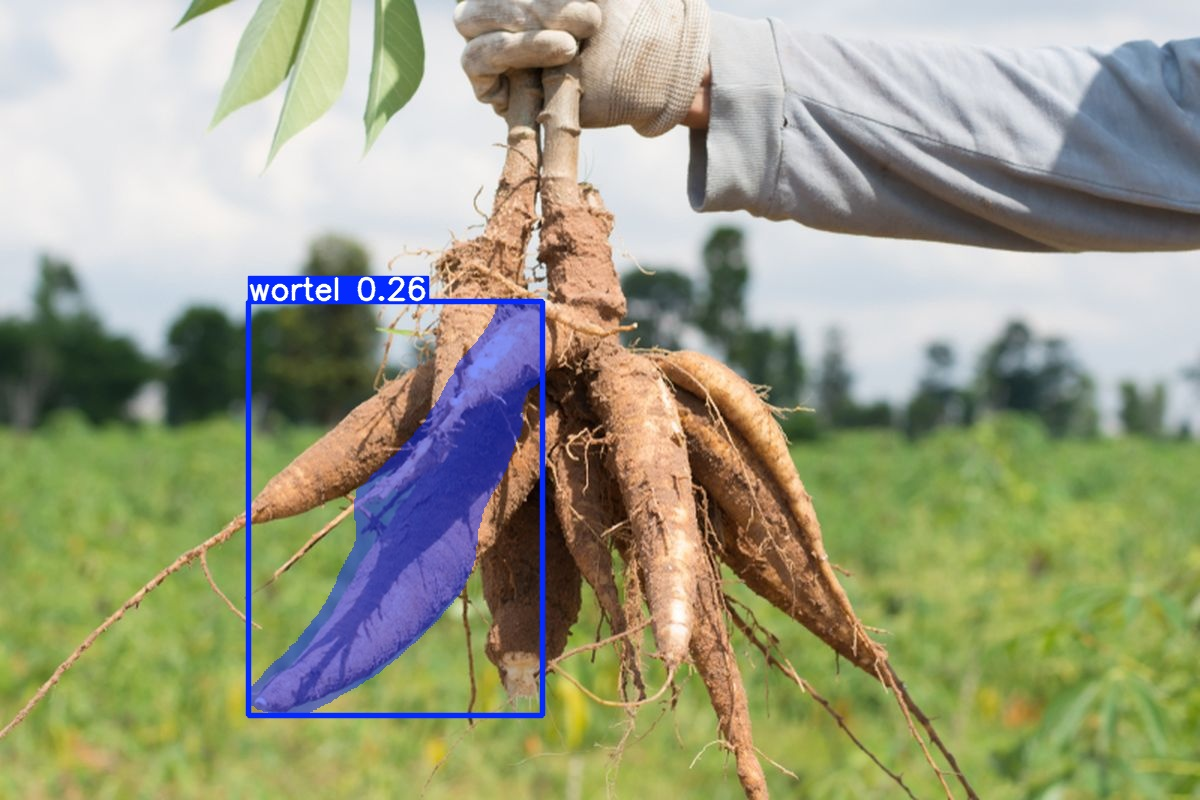


Hasil: 63ec97aa28ed5.jpg


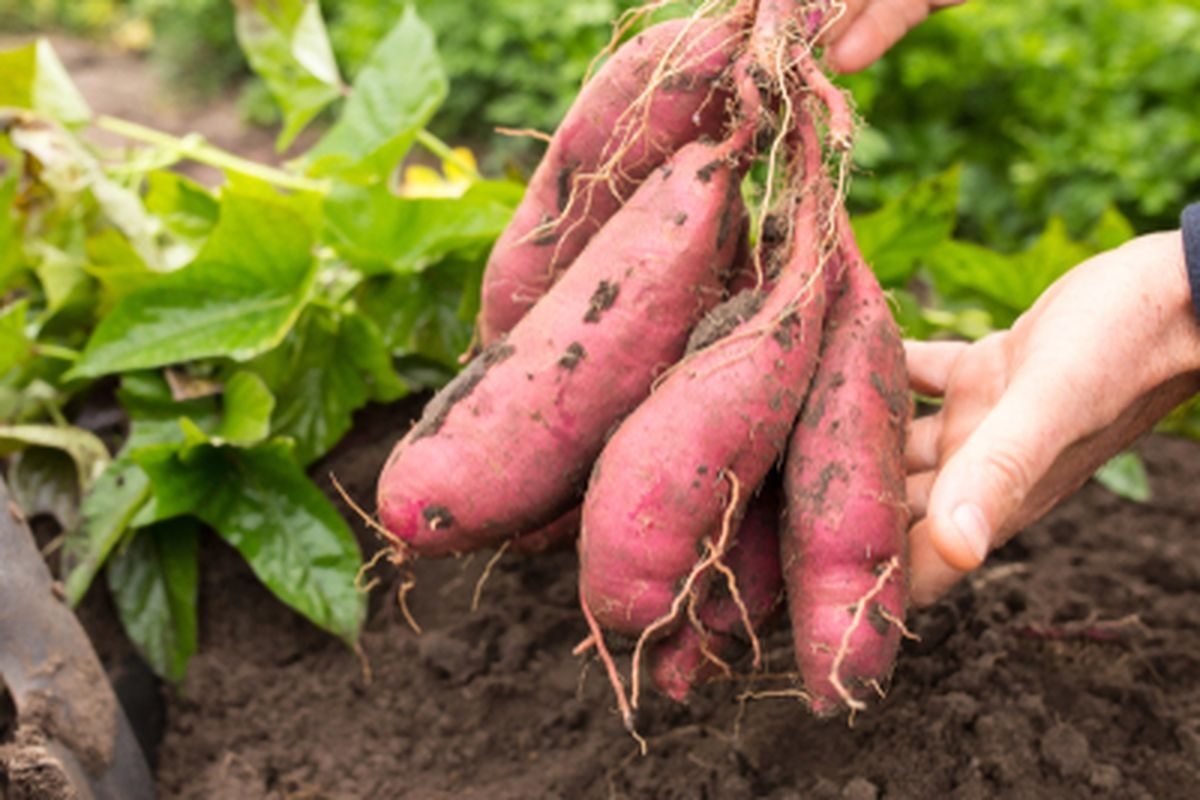


Hasil: Banana_002.jpg


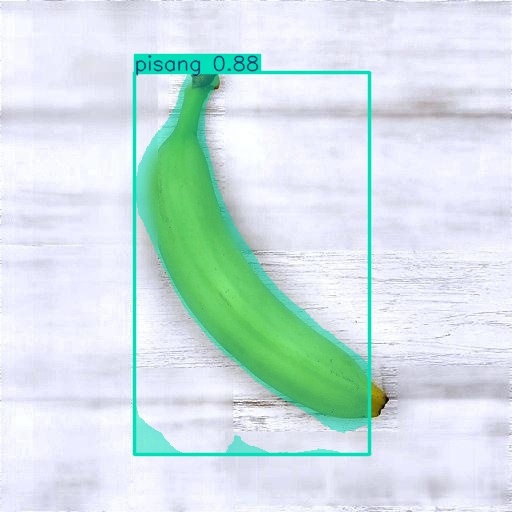


Hasil: bayam11.jpg


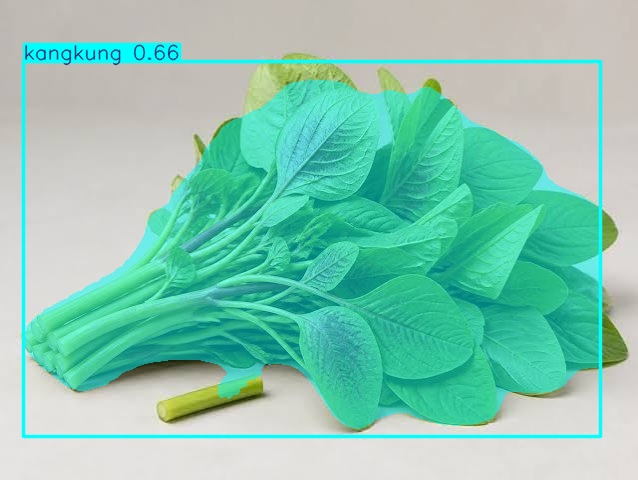


Hasil: bayam2.jpg


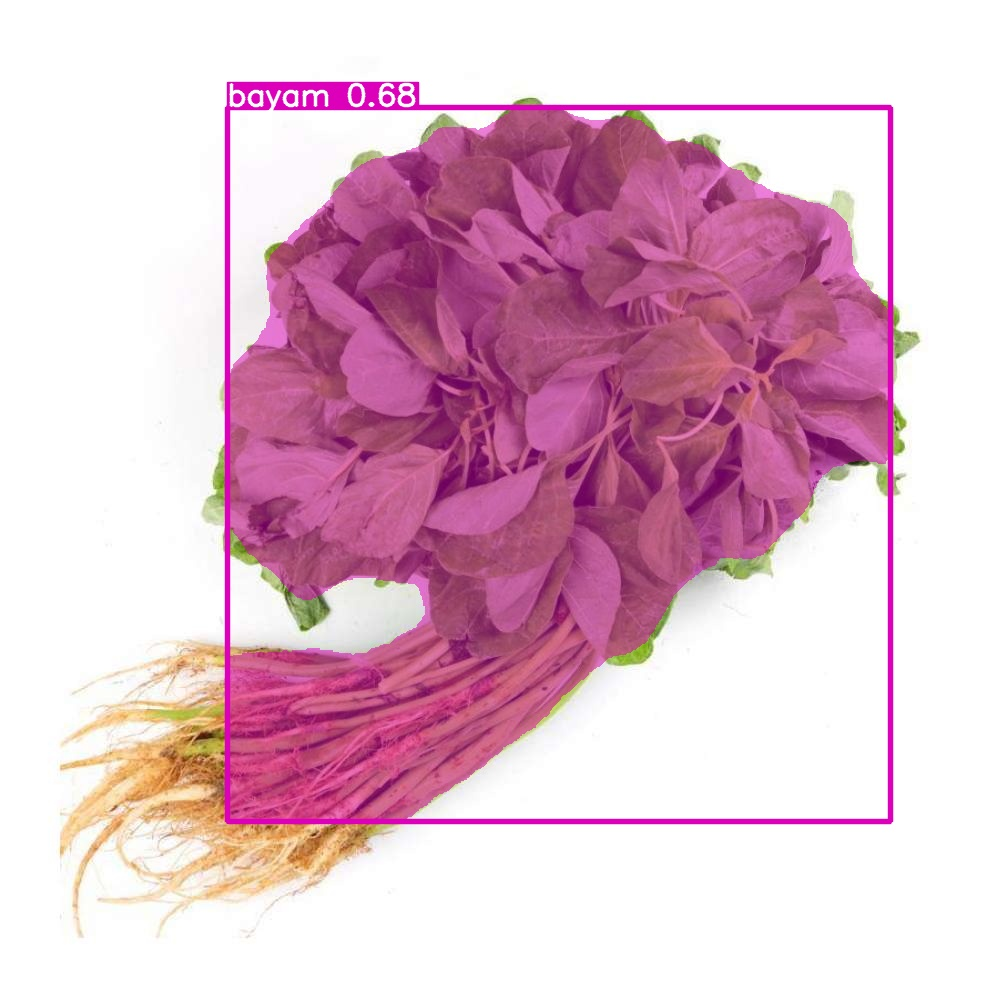

In [65]:

from ultralytics import YOLO
from pathlib import Path
from IPython.display import display, Image as IPImage

ROOT = Path.cwd()

# Muat model PANGANITA
MODEL_PATH = ROOT / "models" / "yolo26n_seg_v1" / "best.pt"

# Gunakan foto testing
TEST_FOLDER = (
    ROOT / "dataset-yolo-stratified" / "images" / "test"
)

# Folder penyimpanan visualisasi
OUTPUT = ROOT / "runs" / "visualisasi_test_v1"

model = YOLO(str(MODEL_PATH))

# Jalankan prediksi
results = model.predict(
    source=str(TEST_FOLDER),
    conf=0.25,
    imgsz=640,
    device="cpu",
    save=True,
    project=str(ROOT / "runs"),
    name="visualisasi_test_v1",
    exist_ok=True
)

print("Jumlah foto diuji:", len(results))
print("Hasil tersimpan:", OUTPUT)

# Tampilkan 5 hasil pertama
from pathlib import Path

extensions = {".jpg", ".jpeg", ".png", ".webp"}

hasil_foto = sorted([
    f for f in OUTPUT.iterdir()
    if f.suffix.lower() in extensions
])

for foto in hasil_foto[:5]:
    print("\nHasil:", foto.name)
    display(IPImage(filename=str(foto)))


In [67]:
from pathlib import Path

from ultralytics import YOLO
from IPython.display import display
from ipywidgets import FileUpload, Button, Output, VBox, HTML
from PIL import Image
import io
import numpy as np
import pandas as pd

# =====================================
# 1. MUAT MODEL PANGANITA
# =====================================

ROOT = Path.cwd()

MODEL_PATH = (
    ROOT / "models" / "yolo26n_seg_v1" / "best.pt"
)

model = YOLO(str(MODEL_PATH))

print("Model YOLO26n-seg berhasil dimuat!")

# =====================================
# 2. KOMPONEN UPLOAD
# =====================================

uploader = FileUpload(
    accept="image/*",
    multiple=True,
    description="Pilih Foto"
)

button = Button(
    description="Prediksi Foto",
    button_style="success",
    icon="search"
)

output = Output()

# =====================================
# 3. PROSES PREDIKSI
# =====================================

def predict_uploaded(change):

    with output:
        output.clear_output()

        files = uploader.value

        if not files:
            print("Silakan upload foto terlebih dahulu.")
            return

        # Kompatibel dengan struktur FileUpload
        if isinstance(files, dict):
            uploaded_files = [
                (name, item["content"])
                for name, item in files.items()
            ]
        else:
            uploaded_files = [
                (item["name"], item["content"])
                for item in files
            ]

        for filename, content in uploaded_files:

            print(f"\nMemproses: {filename}")

            image = Image.open(
                io.BytesIO(bytes(content))
            ).convert("RGB")

            image_np = np.array(image)

            results = model.predict(
                source=image_np,
                conf=0.25,
                imgsz=640,
                device="cpu",
                verbose=False
            )

            result = results[0]

            print("Hasil deteksi:")

            laporan = []

            if result.boxes is not None:
                for box in result.boxes:
                    class_id = int(box.cls.item())
                    confidence = float(box.conf.item())

                    laporan.append({
                        "Nama pangan": model.names[class_id],
                        "Confidence": round(confidence * 100, 2)
                    })

            if laporan:
                display(pd.DataFrame(laporan))
                print("Total objek:", len(laporan))
            else:
                print("Tidak ada objek terdeteksi.")

            # Tampilkan gambar dengan bounding box dan mask
            annotated = result.plot()
            display(
                Image.fromarray(annotated[:, :, ::-1])
            )

# =====================================
# 4. TOMBOL PREDIKSI
# =====================================

button.on_click(predict_uploaded)

display(VBox([
    HTML("<h3>Uji Computer Vision PANGANITA</h3><p>Upload foto pangan dari perangkat kamu.</p>"),
    uploader,
    button,
    output
]))


Model YOLO26n-seg berhasil dimuat!


In [ ]:

from ultralytics import YOLO
from pathlib import Path
from IPython.display import display
from ipywidgets import FileUpload, Button, Output, VBox, HTML
from PIL import Image as PILImage
import numpy as np
import pandas as pd
import io

# 1. LOAD MODEL
ROOT = Path.cwd()
MODEL_PATH = ROOT / "models" / "yolo26n_seg_v1" / "best.pt"

model = YOLO(str(MODEL_PATH))

print("Model berhasil dimuat:", MODEL_PATH)
print("Kelas:", len(model.names))

# 2. INTERFACE UPLOAD
uploader = FileUpload(
    accept="image/*",
    multiple=True,
    description="Upload Foto"
)

button = Button(
    description="Prediksi Foto",
    button_style="success"
)

output = Output()

# 3. FUNGSI PREDIKSI
def predict_uploaded(change):

    with output:
        output.clear_output(wait=True)

        files = uploader.value

        if not files:
            print("Silakan upload foto.")
            return

        if isinstance(files, dict):
            uploaded = [
                (name, item["content"])
                for name, item in files.items()
            ]
        else:
            uploaded = [
                (item["name"], item["content"])
                for item in files
            ]

        print("Jumlah foto diunggah:", len(uploaded))

        for filename, content in uploaded:

            print("\n================================")
            print("FOTO:", filename)

            image = PILImage.open(
                io.BytesIO(bytes(content))
            ).convert("RGB")

            image_np = np.array(image)

            result = model.predict(
                source=image_np,
                conf=0.05,
                imgsz=640,
                device="cpu",
                max_det=300,
                verbose=False
            )[0]

            laporan = []

            if result.boxes is not None:
                for box in result.boxes:

                    class_id = int(box.cls.item())
                    confidence = float(box.conf.item())

                    laporan.append({
                        "Kelas": model.names[class_id],
                        "Confidence (%)": round(
                            confidence * 100, 2
                        )
                    })

            if laporan:
                display(pd.DataFrame(laporan))
                print("Total objek:", len(laporan))
            else:
                print("Tidak ada objek terdeteksi.")

            # PERBAIKAN VISUALISASI
            annotated = result.plot()

            annotated = np.ascontiguousarray(
                annotated[:, :, ::-1]
            )

            display(
                PILImage.fromarray(annotated)
            )

# 4. TAMPILKAN INTERFACE
button.on_click(predict_uploaded)

display(VBox([
    HTML(value="<h3>Pengujian YOLO26-seg PANGANITA</h3>"),
    uploader,
    button,
    output
]))


Model berhasil dimuat: c:\Users\LENOVO\Music\panganita-cv\models\yolo26n_seg_v1\best.pt
Kelas: 15
